# Modelagem do risco de detrator

Este notebook treina e avalia o modelo que estima, logo após a entrega, a probabilidade de o cliente responder à pesquisa de NPS como detrator. A pergunta, o uso do score e o plano de avaliação estão na [estratégia preditiva](../reports/estrategia_preditiva.md), e o plano foi fixado antes do treino (D-18): dois candidatos comparados por validação cruzada no treino, testes de robustez e uma única avaliação no teste, contra a regra de dias de atraso e o modelo ingênuo (D-14 e D-15).

Três regras valem para todo o notebook. O teste só é lido na seção 10, depois da revisão da seção 9, e nenhuma escolha anterior usa os pedidos dele (D-11). A ROC-AUC é a métrica principal, e a PR-AUC, a de apoio (D-12). E, como a base é simulada (D-10), os números valem como demonstração de método.

O modelo final é gerado pelo comando `python -m src.modeling.train`, com a mesma função da seção 2, e fica em `models/`, fora do Git.

In [1]:
# Importações
from loguru import logger
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss, roc_auc_score

# Logs do projeto desligados para não gravar caminhos da máquina local nas saídas
logger.disable("src")

from src.analysis import ranking_metrics
from src.features import load_processed_data
from src.modeling.evaluation import (
    SCORE_RANKING,
    auc_difference,
    calibration_table,
    cv_splits,
    error_by_group,
    out_of_fold,
    permutation_importance_cv,
    reference_criteria,
)
from src.modeling.models import (
    BOOSTING,
    CHECKOUT_FEATURES,
    DELIVERY,
    EXCLUDED,
    FEATURE_LABELS,
    FEATURES,
    LINEAR,
    ORDER,
    PROFILE,
    SEARCH_SPACES,
    SERVICE,
    TARGET,
    build_regressor,
    tune,
    with_features,
)
from src.modeling.predict import LONG_DELAY_DAYS
from src.modeling.train import train_model
from src.plots import ACCENT, INK, plot_calibration, plot_roc_curves, save_figure, set_style
from src.split import TEST, TRAIN, split_train_test

set_style()

# Só o treino até a seção 10; o teste fica separado e intocado (D-11)
processed = load_processed_data()
split = split_train_test(processed)
train = processed[split == TRAIN]
x_train, y_train = train[FEATURES], train[TARGET]
delay_rule = train["delivery_delay_days"]
print(f"{len(train)} pedidos de treino, {y_train.mean():.1%} de detratores")


2000 pedidos de treino, 84.4% de detratores


## 1. Variáveis do modelo

As variáveis são as da D-06, agrupadas pelo momento em que o dado existe: cadastro, pedido, entrega e atendimento. Ficam fora a nota, que define o alvo, o CSAT, a recompra e os identificadores. O modelo recebe as colunas como a base as registra. Os atributos de `src/features.py` repetem essa informação em faixas e indicadores, úteis para ler a análise exploratória, mas dispensáveis aqui: o gradient boosting encontra os próprios cortes, e a análise exploratória não encontrou, nas variáveis associadas aos detratores, ponto de ruptura que pedisse um corte fixo na regressão logística (seção 6 da [análise exploratória](02_eda.ipynb)). A região é a única variável de categoria.

In [2]:
moments = {"cadastro": PROFILE, "pedido": ORDER, "entrega": DELIVERY, "atendimento": SERVICE}

# Nenhuma variável proibida pela D-06 pode entrar no modelo
assert not set(FEATURES) & set(EXCLUDED)
print(f"Fora do modelo: {', '.join(EXCLUDED)}")

pd.DataFrame(
    {
        "variáveis": [", ".join(columns) for columns in moments.values()],
        "no cenário de checkout": [
            set(columns) <= set(CHECKOUT_FEATURES) for columns in moments.values()
        ],
    },
    index=list(moments),
)


Fora do modelo: nps_score, csat_internal_score, repeat_purchase_30d, customer_id, order_id


,variáveis,no cenário de checkout
cadastro,"customer_age, customer_region, customer_tenure...",True
pedido,"order_value, items_quantity, discount_value, p...",True
entrega,"delivery_time_days, delivery_delay_days, deliv...",False
atendimento,"customer_service_contacts, resolution_time_day...",False


## 2. Candidatos na validação cruzada

Regressão logística e gradient boosting, cada um com 20 combinações de hiperparâmetros sorteadas e medidas nas mesmas cinco partes do treino, estratificadas pela variável-alvo (D-18). A melhor combinação de cada candidato prevê depois o risco de todos os pedidos de treino fora da amostra: cada pedido recebe o risco de um modelo ajustado sem ele. São essas previsões que comparam os candidatos entre si e com as referências, o modelo ingênuo e a regra de dias de atraso, que não têm nada a ajustar e são medidas no treino inteiro. Vence o candidato de maior ROC-AUC ou, se a diferença for de até 0,01, a regressão logística, o mais simples dos dois. Como a busca escolhe os hiperparâmetros nas mesmas partes que medem o resultado, a estimativa sai levemente otimista; a palavra final é do teste.

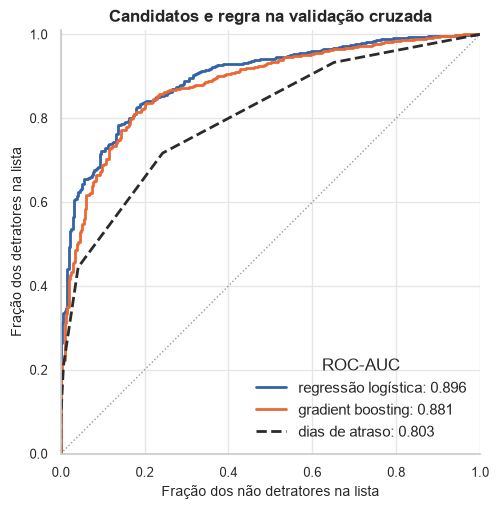

,hiperparâmetros,escolhido
regressão logística,{'C': 0.1445},True
gradient boosting,"{'l2_regularization': 0.004937, 'learning_rate...",False


,PR-AUC,ROC-AUC,precisão no topo,captura no topo
regressão logística,0.978,0.896,1.000,0.237
gradient boosting,0.974,0.881,0.992,0.235
dias de atraso,0.944,0.803,0.995,0.236
modelo ingênuo,0.844,0.500,0.840,0.199


In [3]:
model, candidates, cv_risk = train_model(train)
chosen = candidates.index[candidates["escolhido"]][0]
scores = {**cv_risk, "dias de atraso": delay_rule}

fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_roc_curves(
    y_train,
    scores,
    reference="dias de atraso",
    ax=ax,
    title="Candidatos e regra na validação cruzada",
)
save_figure(fig, "modelo_02_candidatos")
plt.show()

display(candidates[["hiperparâmetros", "escolhido"]])
references = {**scores, "modelo ingênuo": np.zeros(len(train))}
pd.DataFrame(
    {name: ranking_metrics(y_train, score) for name, score in references.items()}
).T.round(3)


**A regressão logística vence por desempenho, e não pelo desempate: supera o gradient boosting por uma diferença maior que a margem de 0,01 e fica acima da regra de dias de atraso em toda a curva.** Num par sorteado de detrator e não detrator, o modelo dá o risco maior ao detrator cerca de nove em cada dez vezes, contra oito da regra, que não tem como ordenar pedidos com os mesmos dias de atraso: são os trechos retos da curva dela. No topo de 20% da lista, os dois candidatos e a regra reúnem quase só detratores, e por isso precisão e captura não separam as ordenações, como a D-12 previa.

## 3. Regressão da nota como comparação

A alternativa à classificação é prever a nota, de 0 a 10, e ordenar os clientes da menor para a maior nota prevista (D-17). Entram as duas famílias, regressão linear com regularização e gradient boosting, com a mesma busca, as mesmas partes e as mesmas variáveis dos candidatos. A busca da regressão escolhe os hiperparâmetros pela própria ROC-AUC da ordenação, para a comparação não favorecer a classificação. Se a melhor regressão ordenar melhor que o candidato escolhido, a escolha é revista antes do teste.

In [4]:
splits = cv_splits(x_train, y_train)
orderings = {f"classificação: {chosen}": cv_risk[chosen]}
for kind in [LINEAR, BOOSTING]:
    search = tune(
        build_regressor(kind),
        SEARCH_SPACES[kind],
        x_train,
        train["nps_score"],
        splits,
        scoring=SCORE_RANKING,
    )
    # Nota prevista menor, risco maior
    predicted_score = out_of_fold(search.best_estimator_, x_train, train["nps_score"], splits)
    orderings[f"regressão: {kind}"] = -predicted_score

comparison = pd.DataFrame(
    {name: ranking_metrics(y_train, score) for name, score in orderings.items()}
).T
best_regression = comparison.iloc[1:]["ROC-AUC"].idxmax()
display(comparison.round(3))

difference = auc_difference(y_train, cv_risk[chosen], orderings[best_regression])
pd.DataFrame({f"classificação menos {best_regression}": difference}).T.round(3)


,PR-AUC,ROC-AUC,precisão no topo,captura no topo
classificação: regressão logística,0.978,0.896,1.0,0.237
regressão: regressão linear,0.979,0.898,1.0,0.237
regressão: gradient boosting,0.978,0.894,1.0,0.237


,diferença,IC inferior,IC superior
classificação menos regressão: regressão linear,-0.002,-0.006,0.002


**Prever a nota não ordena os clientes melhor que prever o detrator: a melhor regressão empata com a regressão logística, e a diferença entre as duas fica dentro do acaso.** O intervalo da diferença cruza o zero, e nas três ordenações o topo de 20% da lista só tem detratores. Com a ordenação empatada, a escolha da D-17 se apoia nos argumentos de negócio: a probabilidade de detrator responde à meta e à decisão de pôr ou não o cliente na lista, e a nota prevista, não.

## 4. Pedidos com até 2 dias de atraso

Na lista do dia, os pedidos com 3 dias de atraso ou mais seguem a regra, e o modelo ordena só os demais (D-19). É nesse segmento que o ganho sobre a regra precisa aparecer: o risco previsto na validação cruzada e os dias de atraso são comparados só nesses pedidos, pela ROC-AUC, com intervalo bootstrap de 95% da diferença.

1237 pedidos com até 2 dias de atraso, 75.7% de detratores


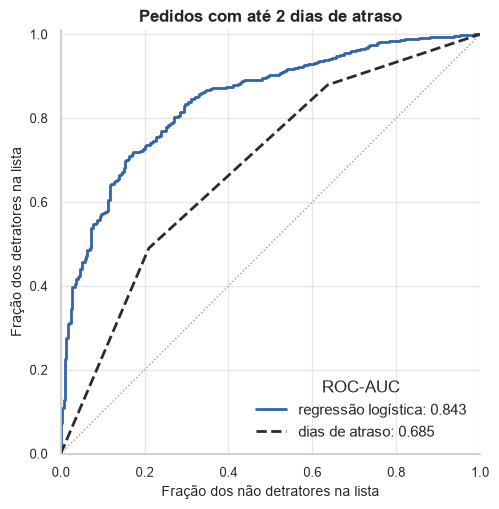

,PR-AUC,ROC-AUC,precisão no topo,captura no topo
regressão logística,0.941,0.843,0.984,0.259
dias de atraso,0.838,0.685,0.874,0.231


,diferença,IC inferior,IC superior
modelo menos regra,0.158,0.13,0.188


In [5]:
short = (delay_rule < LONG_DELAY_DAYS).to_numpy()
segment = {chosen: cv_risk[chosen][short], "dias de atraso": delay_rule[short]}
print(f"{short.sum()} pedidos com até 2 dias de atraso, {y_train[short].mean():.1%} de detratores")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_roc_curves(
    y_train[short],
    segment,
    reference="dias de atraso",
    ax=ax,
    title="Pedidos com até 2 dias de atraso",
)
save_figure(fig, "modelo_04_ate_2_dias_de_atraso")
plt.show()

display(
    pd.DataFrame(
        {name: ranking_metrics(y_train[short], score) for name, score in segment.items()}
    ).T.round(3)
)
segment_difference = auc_difference(y_train[short], cv_risk[chosen][short], delay_rule[short])
pd.DataFrame({"modelo menos regra": segment_difference}).T.round(3)


**É nos pedidos com até 2 dias de atraso, seis em cada dez do treino, que o modelo mais se distancia da regra, justamente onde a D-19 o põe para ordenar a lista do dia.** Com o atraso limitado a zero, um ou dois dias, a curva da regra se resume a três trechos retos, e, num par sorteado de detrator e não detrator, ela põe o detrator na frente cerca de sete em cada dez vezes, contra pouco mais de oito do modelo, com o intervalo da diferença longe de zero. No topo da lista, quase todos os clientes escolhidos pelo modelo são detratores, contra pouco menos de nove em cada dez na ordem da regra.

## 5. Robustez das variáveis

O candidato escolhido é treinado de novo com outros conjuntos de variáveis, com os mesmos hiperparâmetros e as mesmas partes: sem `complaints_count`, sinal muito próximo da própria nota (D-16); sem `resolution_time_days`, que a base traz com o valor final, e não com o do momento da predição (D-06); no cenário de checkout, só com cadastro e pedido (D-04); e com o CSAT, que fica fora do modelo pelo risco de vazamento, para medir quanto ele mudaria o desempenho (D-06). A diferença para o modelo com todas as variáveis vem com intervalo bootstrap de 95%, e o ganho sobre a regra de dias de atraso mostra quanto da vantagem resiste em cada cenário.

In [6]:
variants = {
    "todas as variáveis": FEATURES,
    "sem complaints_count": [column for column in FEATURES if column != "complaints_count"],
    "sem resolution_time_days": [
        column for column in FEATURES if column != "resolution_time_days"
    ],
    "checkout: cadastro e pedido": CHECKOUT_FEATURES,
    "com o CSAT": [*FEATURES, "csat_internal_score"],
}
variant_risk = {
    name: out_of_fold(with_features(model, columns), train[columns], y_train, splits)
    for name, columns in variants.items()
}

rule_auc = roc_auc_score(y_train, delay_rule)
rows = {}
for name, risk in variant_risk.items():
    auc = roc_auc_score(y_train, risk)
    rows[name] = {"ROC-AUC": auc, "ganho sobre a regra": auc - rule_auc}
    if name != "todas as variáveis":
        rows[name] |= auc_difference(y_train, risk, variant_risk["todas as variáveis"])
pd.DataFrame(rows).T.rename(columns={"diferença": "diferença para todas"}).round(3)


,ROC-AUC,ganho sobre a regra,diferença para todas,IC inferior,IC superior
todas as variáveis,0.896,0.093,NaN,NaN,NaN
sem complaints_count,0.875,0.071,-0.022,-0.031,-0.012
sem resolution_time_days,0.880,0.076,-0.017,-0.025,-0.008
checkout: cadastro e pedido,0.527,-0.276,-0.369,-0.405,-0.330
com o CSAT,0.895,0.092,-0.001,-0.002,-0.000


**O ganho sobre a regra não depende de uma variável só: sem as reclamações, o modelo conserva cerca de três quartos da vantagem e, sem o tempo de resolução, cerca de quatro quintos.** As duas quedas são pequenas, mas com o intervalo inteiro abaixo de zero, e a vantagem não vem quase toda da reclamação, o caso em que a D-16 pediria ressalva. No checkout, só com cadastro e pedido, o modelo fica perto do sorteio, porque quase todo o sinal está na entrega e no atendimento; e o treino com o CSAT não mostra o desempenho inflado que a D-06 temia, porque o CSAT não acrescenta nada ao que as outras variáveis já trazem.

## 6. O que o modelo usa

A importância de cada variável é a queda da ROC-AUC quando os valores dela são embaralhados entre os pedidos, medida em cada parte de validação pelo modelo ajustado sem ela, dez vezes por variável. Variáveis que carregam a mesma informação dividem a importância entre si. A leitura confere se o modelo se apoia nos sinais que a análise exploratória encontrou; a ação sobre o cliente não depende dela, porque segue a falha registrada no pedido (D-19).

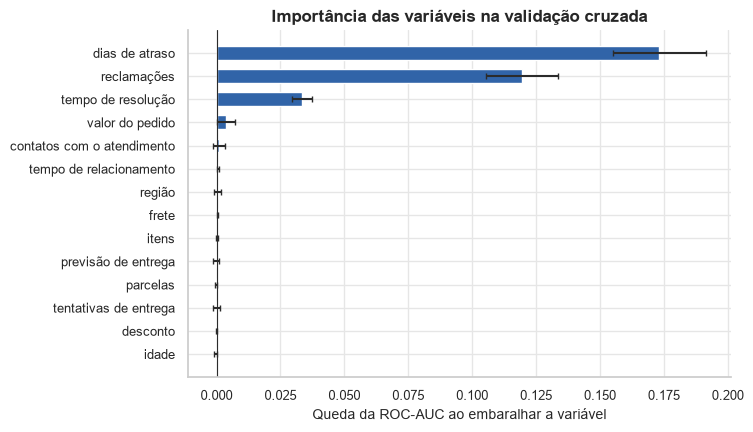

,queda da ROC-AUC,desvio entre as partes
delivery_delay_days,0.1733,0.0182
complaints_count,0.1194,0.0140
resolution_time_days,0.0334,0.0038
order_value,0.0036,0.0037
customer_service_contacts,0.0010,0.0024
customer_tenure_months,0.0006,0.0004
customer_region,0.0004,0.0014
freight_value,0.0004,0.0003
items_quantity,0.0001,0.0005
delivery_time_days,-0.0000,0.0012


In [7]:
importance = permutation_importance_cv(model, x_train, y_train, splits)
ordered = importance.sort_values("queda da ROC-AUC").rename(index=FEATURE_LABELS)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(
    ordered.index,
    ordered["queda da ROC-AUC"],
    xerr=ordered["desvio entre as partes"],
    height=0.6,
    color=ACCENT,
    ecolor=INK,
    capsize=2,
)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Queda da ROC-AUC ao embaralhar a variável")
ax.set_title("Importância das variáveis na validação cruzada")
save_figure(fig, "modelo_06_importancia")
plt.show()

importance.round(4)


**O modelo se apoia em três sinais: os dias de atraso e as reclamações, os dois que a análise exploratória colocou à frente, e, bem atrás, o tempo de resolução.** As outras onze variáveis quase não mudam a ordenação quando embaralhadas, inclusive os contatos com o atendimento, associados aos detratores na análise exploratória, mas que pouco acrescentam a um modelo que já tem as reclamações e o tempo de resolução. Idade, região e tempo de relacionamento estão entre elas: a ordem da lista não depende de quem é o cliente, como a análise exploratória já indicava.

## 7. Calibração das probabilidades

O risco previsto também estima quantos detratores a lista do dia alcança, e para isso precisa corresponder à proporção observada (D-18). Os pedidos de treino se dividem em dez faixas de risco previsto na validação cruzada, com o mesmo número de pedidos, e cada faixa compara o risco médio previsto com a proporção observada de detratores, com intervalo de Wilson de 95%. O escore de Brier resume o erro das probabilidades e é lido contra o do modelo ingênuo, que prevê a mesma proporção para todos.

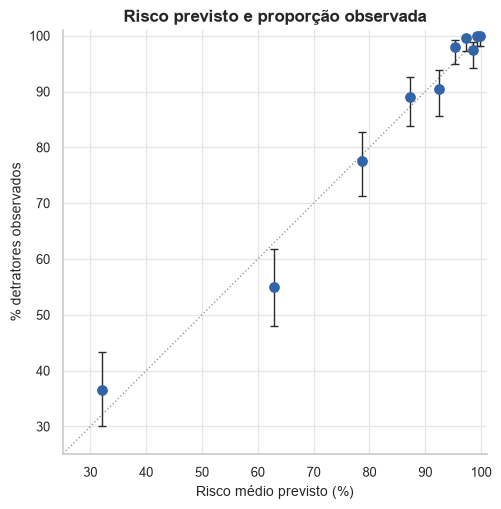

,escore de Brier
regressão logística,0.0867
modelo ingênuo,0.1320


,pedidos,% previsto,% detratores,IC inferior,IC superior
faixa de risco,,,,,
1,200,32.1,36.5,30.1,43.4
2,200,62.8,55.0,48.1,61.7
3,200,78.6,77.5,71.2,82.7
4,200,87.3,89.0,83.9,92.6
5,200,92.5,90.5,85.6,93.8
6,200,95.4,98.0,95.0,99.2
7,200,97.3,99.5,97.2,99.9
8,200,98.5,97.5,94.3,98.9
9,200,99.3,100.0,98.1,100.0


In [8]:
calibration = calibration_table(y_train, cv_risk[chosen])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_calibration(calibration, ax=ax, title="Risco previsto e proporção observada")
save_figure(fig, "modelo_07_calibracao")
plt.show()

brier = {
    chosen: brier_score_loss(y_train, cv_risk[chosen]),
    "modelo ingênuo": brier_score_loss(y_train, np.full(len(train), y_train.mean())),
}
display(pd.Series(brier, name="escore de Brier").round(4).to_frame())
calibration.round(1)


**As probabilidades acompanham a proporção observada: em nove das dez faixas, o risco previsto cai dentro do intervalo da proporção de detratores.** A exceção é a segunda faixa de menor risco, em que o modelo prevê cerca de seis detratores em cada dez e aparecem pouco mais de cinco; nas faixas de risco alto, de onde sai a lista do dia, previsto e observado praticamente coincidem. O escore de Brier fica cerca de um terço abaixo do modelo ingênuo, e a probabilidade serve para estimar quantos detratores a lista alcança.

## 8. Erro por região e faixa de idade

Região e idade não definem ação (D-19), mas o modelo pode errar mais para um grupo do que para outro. Em cada região e faixa de idade, o risco médio previsto na validação cruzada é comparado com a proporção observada de detratores, e a ROC-AUC mostra se o modelo ordena os clientes daquele grupo tão bem quanto os dos demais. O número de pedidos de cada grupo limita a precisão das diferenças.

In [9]:
groups = {"região": train["customer_region"], "faixa de idade": train["age_bucket"]}
pd.concat(
    {name: error_by_group(y_train, cv_risk[chosen], group) for name, group in groups.items()}
).round(3)


pedidos  % detratores  % previsto  \
região         Centro-Oeste      374        85.027      85.059   
               Nordeste          381        85.564      85.202   
               Norte             403        84.864      84.707   
               Sudeste           413        84.262      84.596   
               Sul               429        82.284      82.421   
faixa de idade 18 a 24           264        84.848      85.919   
               25 a 34           366        80.874      83.186   
               35 a 44           407        88.698      84.661   
               45 a 54           389        83.290      84.299   
               55 ou mais        574        83.972      84.199   

                             diferença (pontos)  ROC-AUC  
região         Centro-Oeste               0.032    0.917  
               Nordeste                  -0.363    0.895  
               Norte                     -0.156    0.895  
               Sudeste                    0.334    0.894  
               Sul                        0.137    0.882  
faixa de idade 18 a 24                    1.070    0.891  
               25 a 34                    2.311    0.872  
               35 a 44                   -4.037    0.935  
               45 a 54                    1.008    0.896  
               55 ou mais                 0.227    0.891

**O modelo erra pouco e de forma parecida entre os grupos: nas regiões, o risco previsto fica a menos de meio ponto da proporção observada, e a ROC-AUC de cada região e faixa de idade fica perto da do treino inteiro.** A maior diferença está na idade, com o risco subestimado em cerca de quatro pontos na faixa de 35 a 44 anos e superestimado em pouco mais de dois na de 25 a 34, perto do que grupos de algumas centenas de pedidos explicam. Como o modelo praticamente não usa a idade (seção 6), a diferença vem da proporção observada, que oscila entre as faixas sem padrão, como na análise exploratória, e não de um tratamento diferente por idade.

## 9. Portão antes do teste

As respostas que liberam o teste, cada uma com a evidência das seções anteriores. Uma resposta que pedisse mudança no plano da D-18 entraria como nova decisão, registrada antes da seção 10.

- **Candidato escolhido:** regressão logística, com ROC-AUC de 0,896 na validação cruzada, contra 0,881 do gradient boosting. A diferença, de 0,015, passa da margem de 0,01, e a escolha sai da maior ROC-AUC, e não do desempate pelo mais simples; o C escolhido, de 0,1445, fica longe dos limites da faixa da busca (seção 2; D-18).
- **Regressão da nota:** empata com a classificação. A melhor regressão, a linear, chega a 0,898, e a diferença da classificação para ela é de −0,002, com intervalo de −0,006 a +0,002: cruza o zero e fica abaixo da margem de 0,01 que a D-18 trata como empate. Sem ordenação melhor, a condição da D-17 para rever a escolha não se cumpre (seção 3).
- **Ganho nos pedidos com até 2 dias de atraso:** ROC-AUC de 0,843 do modelo, contra 0,685 da regra, uma diferença de 0,158, com intervalo de 0,130 a 0,188. O ganho aparece onde a D-19 põe o modelo para ordenar a lista (seção 4).
- **Robustez das variáveis:** sem `complaints_count`, o ganho sobre a regra passa de 0,093 para 0,071; sem `resolution_time_days`, para 0,076. A vantagem não vem quase toda da reclamação, e a ressalva da D-16 não se aplica. O cenário de checkout fica em 0,527, perto do modelo ingênuo, e o treino com o CSAT não melhora o desempenho, sem o ganho artificial que a D-06 esperava (seção 5).
- **Calibração:** em nove das dez faixas, o risco previsto cai dentro do intervalo da proporção observada; a exceção é a segunda faixa de menor risco, superestimada em cerca de oito pontos. O escore de Brier é de 0,087, contra 0,132 do modelo ingênuo, e as probabilidades servem para estimar o impacto da lista sem recalibração (seção 7).
- **Erro por grupo:** nas regiões, o risco previsto fica a menos de meio ponto da proporção observada; na idade, a maior diferença é de cerca de quatro pontos, na faixa de 35 a 44 anos, perto da variação esperada em grupos de algumas centenas de pedidos. A ROC-AUC vai de 0,872 a 0,935 entre os grupos, e o modelo praticamente não usa idade nem região (seções 6 e 8).
- **Plano do teste:** sem mudança na D-18 e sem decisão nova. O teste avalia uma única vez a regressão logística, reajustada com todo o treino, contra a regra de dias de atraso e o modelo ingênuo, pelos três critérios da D-15, e repete a comparação nos pedidos com até 2 dias de atraso (D-19).

## 10. Avaliação no teste

Os 500 pedidos de teste, separados antes da análise exploratória (D-11), são usados uma única vez, para o modelo escolhido, treinado com todo o treino, a regra de dias de atraso e o modelo ingênuo. O modelo supera a regra se a ROC-AUC ficar pelo menos 0,05 acima da dela, com o intervalo bootstrap de 95% da diferença acima de zero, e se a PR-AUC não ficar abaixo da dela (D-15). Precisão e captura no topo de 20% descrevem a lista, sem peso na decisão (D-12). A mesma comparação nos pedidos com até 2 dias de atraso mostra se o ganho aparece onde o modelo vai ser usado (D-19).

500 pedidos de teste, 84.4% de detratores; 301 com até 2 dias de atraso


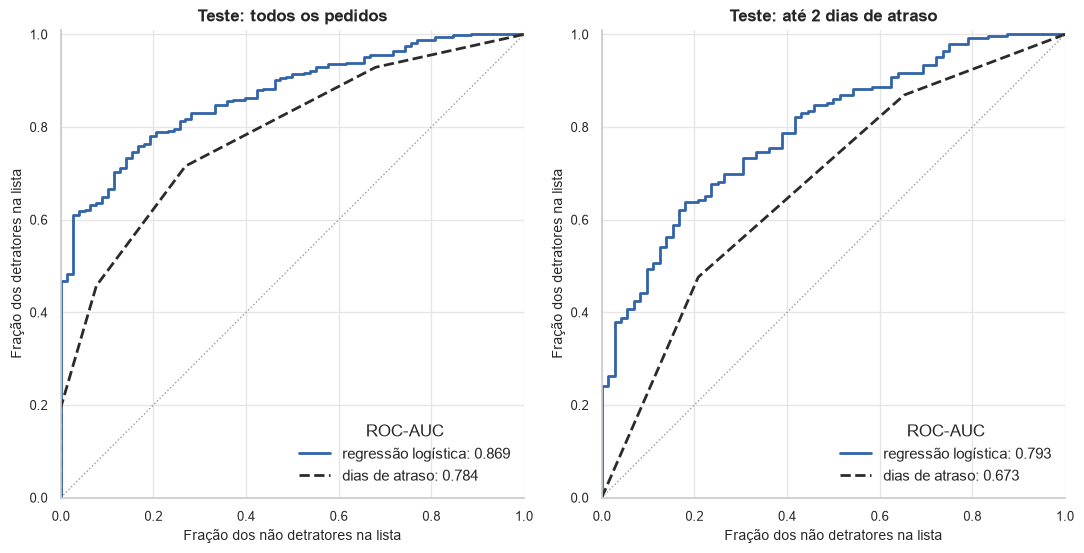

,PR-AUC,ROC-AUC,precisão no topo,captura no topo
regressão logística,0.974,0.869,1.00,0.237
dias de atraso,0.939,0.784,1.00,0.237
modelo ingênuo,0.844,0.500,0.87,0.206


,diferença,IC inferior,IC superior
todos os pedidos,0.085,0.044,0.129
até 2 dias de atraso,0.120,0.056,0.183


Critério da D-15: atingido


,atendido
ROC-AUC pelo menos 0.05 acima da regra,True
intervalo da diferença acima de zero,True
PR-AUC não menor que a da regra,True


In [ ]:
test = processed[split == TEST]
y_test, test_rule = test[TARGET], test["delivery_delay_days"]
test_risk = model.predict_proba(test[FEATURES])[:, 1]
test_short = (test_rule < LONG_DELAY_DAYS).to_numpy()
print(
    f"{len(test)} pedidos de teste, {y_test.mean():.1%} de detratores; "
    f"{test_short.sum()} com até 2 dias de atraso"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
plot_roc_curves(
    y_test,
    {chosen: test_risk, "dias de atraso": test_rule},
    reference="dias de atraso",
    ax=axes[0],
    title="Teste: todos os pedidos",
)
plot_roc_curves(
    y_test[test_short],
    {chosen: test_risk[test_short], "dias de atraso": test_rule[test_short]},
    reference="dias de atraso",
    ax=axes[1],
    title="Teste: até 2 dias de atraso",
)
fig.tight_layout()
save_figure(fig, "modelo_10_teste")
plt.show()

test_scores = {
    chosen: test_risk,
    "dias de atraso": test_rule,
    "modelo ingênuo": np.zeros(len(test)),
}
results = pd.DataFrame(
    {name: ranking_metrics(y_test, score) for name, score in test_scores.items()}
).T
differences = pd.DataFrame(
    {
        "todos os pedidos": auc_difference(y_test, test_risk, test_rule),
        "até 2 dias de atraso": auc_difference(
            y_test[test_short], test_risk[test_short], test_rule[test_short]
        ),
    }
).T
display(results.round(3))
display(differences.round(3))

criteria = reference_criteria(
    differences.loc["todos os pedidos"],
    results.loc[chosen, "PR-AUC"],
    results.loc["dias de atraso", "PR-AUC"],
)
print(f"Critério da D-15: {'atingido' if criteria.all() else 'não atingido'}")
criteria.to_frame("atendido")


**O modelo supera a regra de dias de atraso no teste com um ganho perto do que a validação cruzada estimava, e a vantagem segue maior nos pedidos com até 2 dias de atraso, onde ele vai ser usado.** A ROC-AUC dos dois cai um pouco em relação ao treino, inclusive a da regra, que não tem nada a ajustar, sinal de que a queda vem mais da amostra de teste do que do otimismo da busca de hiperparâmetros (seção 2). Com 500 pedidos, o intervalo da diferença fica acima de zero, mas começa abaixo da margem de 0,05 e não descarta um ganho real um pouco menor que ela; nos pedidos com até 2 dias de atraso, seis em cada dez do teste, o intervalo fica todo acima da margem.